# Predicting Life Expectancy Using Economic and Social Indicators

## 1. Business Understanding

Life expectancy is an important indicator of a country's overall health and development. Economic conditions, healthcare investment, and access to essential services may influence how long people live.

This project investigates the relationship between economic and social indicators and life expectancy using data from the World Bank.

### Research Questions

1. How does GDP per capita relate to life expectancy?
2. Does healthcare expenditure have a relationship with life expectancy?
3. How do electricity access and unemployment relate to life expectancy?
4. Can machine learning models accurately predict life expectancy using economic and social indicators?

### Project Objective

The main objective is to develop and evaluate machine learning regression models capable of predicting life expectancy based on economic and social indicators.

## 2. Data Understanding

The dataset contains observations from countries between 2010 and 2022.

The target variable is **Life_Expectancy**, measured in years.

The predictive features are:
- GDP_Per_Capita
- Health_Expenditure
- Electricity_Access
- Unemployment

The analysis begins with an examination of data quality, descriptive statistics, distributions, and correlations.

In [1]:
# Import libraries for data preparation, modeling, and visualization.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline

print("All libraries imported successfully!")


All libraries imported successfully!


### 2.1 Data Gathering

The [World Bank World Development Indicators](https://data.worldbank.org/) provide the country-year observations. The reproducible data snapshot is stored in `World_Bank_Life_Expectancy.csv`. The original collection used World Bank indicators `SP.DYN.LE00.IN`, `NY.GDP.PCAP.CD`, `SH.XPD.CHEX.GD.ZS`, `EG.ELC.ACCS.ZS`, and `SL.UEM.TOTL.ZS`.

The archived data cover 217 countries and economies from 2010 to 2022. Using the original CSV instead of downloading an updated dataset ensures that the reported results remain reproducible.


In [2]:
# Load the original World Bank dataset committed with this notebook.
# Using this archived CSV avoids API revisions and does not require internet.
DATA_PATH = Path("World_Bank_Life_Expectancy.csv")


def load_world_bank_dataset(path: Path) -> pd.DataFrame:
    """Load and validate the project's frozen country-year dataset."""
    if not path.is_file():
        raise FileNotFoundError(
            f"Dataset not found: {path}. "
            "Download World_Bank_Life_Expectancy.csv from the repository."
        )

    dataset = pd.read_csv(path)
    expected_columns = {
        "Country",
        "Country_Code",
        "Year",
        "Electricity_Access",
        "GDP_Per_Capita",
        "Health_Expenditure",
        "Life_Expectancy",
        "Unemployment",
    }
    missing_columns = expected_columns.difference(dataset.columns)

    if missing_columns:
        raise ValueError(
            f"Dataset is missing expected columns: {sorted(missing_columns)}"
        )

    if dataset["Life_Expectancy"].isna().any():
        raise ValueError("The target column contains missing values.")

    return dataset


df = load_world_bank_dataset(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (2821, 8)


,Country,Country_Code,Year,Electricity_Access,GDP_Per_Capita,Health_Expenditure,Life_Expectancy,Unemployment
0,Afghanistan,AFG,2010,42.7,560.621505,8.569672,60.702,7.809
1,Afghanistan,AFG,2011,43.2,606.694676,8.561908,61.250,7.830
2,Afghanistan,AFG,2012,69.1,651.417134,7.897169,61.735,7.875
3,Afghanistan,AFG,2013,68.0,637.087099,8.805964,62.188,7.921
4,Afghanistan,AFG,2014,89.5,625.054942,9.528878,62.260,7.915


### 2.2 Data Assessment

Assess column types, missingness, duplicate records, summary statistics, countries, and years. Categorical country identifiers are used for descriptive analysis, not for the regression predictors.


In [3]:
# Dataset overview
print("Dataset shape:", df.shape)

print("\nData types:")
df.info()

# Missing values
missing_values = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

print("\nMissing values:")
display(missing_values)

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

print(
    "Duplicate country-year combinations:",
    df.duplicated(subset=["Country_Code", "Year"]).sum()
)

# Descriptive statistics
print("\nDescriptive statistics:")
display(df.describe())

# Countries and years
print("\nNumber of countries:", df["Country_Code"].nunique())
print("Year range:", df["Year"].min(), "-", df["Year"].max())

Dataset shape: (2821, 8)

Data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2821 entries, 0 to 2820
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Country             2821 non-null   object 
 1   Country_Code        2821 non-null   object 
 2   Year                2821 non-null   int64  
 3   Electricity_Access  2795 non-null   float64
 4   GDP_Per_Capita      2749 non-null   float64
 5   Health_Expenditure  2486 non-null   float64
 6   Life_Expectancy     2821 non-null   float64
 7   Unemployment        2430 non-null   float64
dtypes: float64(5), int64(1), object(2)
memory usage: 176.4+ KB

Missing values:


,Missing Values,Missing Percentage
Country,0,0.00
Country_Code,0,0.00
Year,0,0.00
Electricity_Access,26,0.92
GDP_Per_Capita,72,2.55
Health_Expenditure,335,11.88
Life_Expectancy,0,0.00
Unemployment,391,13.86



Duplicate records: 0
Duplicate country-year combinations: 0

Descriptive statistics:


,Year,Electricity_Access,GDP_Per_Capita,Health_Expenditure,Life_Expectancy,Unemployment
count,2821.000000,2795.00000,2749.000000,2486.000000,2821.000000,2430.000000
mean,2016.000000,84.04483,18444.657821,6.503366,72.097746,7.973125
std,3.742321,26.49318,27176.859368,2.926032,8.166766,5.996896
min,2010.000000,1.50000,216.727705,1.543096,18.818000,0.100000
25%,2013.000000,77.25000,2322.890696,4.331461,66.457000,3.744000
50%,2016.000000,99.70000,6729.846599,6.036038,73.331000,5.997000
75%,2019.000000,100.00000,23933.993942,8.335603,78.117000,10.860250
max,2022.000000,100.00000,226052.060665,24.457632,86.151000,36.472000



Number of countries: 217
Year range: 2010 - 2022


### 2.3 Distribution and Correlation Visualizations

Histogram plots reveal skew and extreme values. The Pearson correlation heatmap is descriptive; missing values are omitted pairwise by pandas when computing correlations. Correlation does not imply causation.


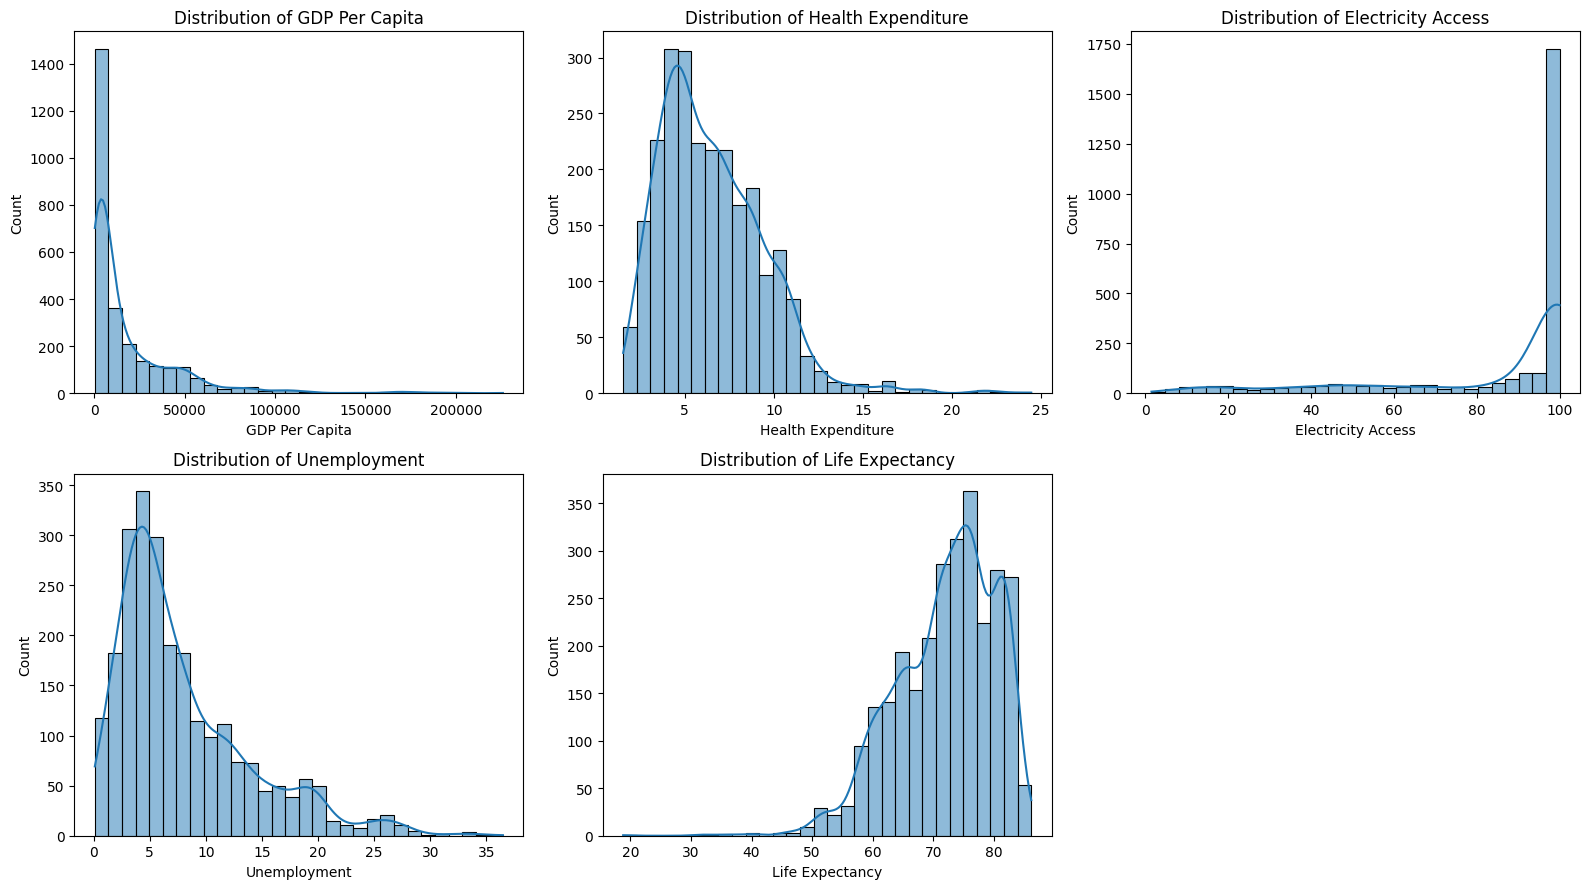

In [4]:
# Numerical variables
features = [
    "GDP_Per_Capita",
    "Health_Expenditure",
    "Electricity_Access",
    "Unemployment",
    "Life_Expectancy"
]

# Plot distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, column in zip(axes.flat, features):
    sns.histplot(
        data=df,
        x=column,
        bins=30,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution of {column.replace('_', ' ')}")
    ax.set_xlabel(column.replace("_", " "))

# Remove unused subplot
fig.delaxes(axes.flat[-1])

plt.tight_layout()
plt.show()

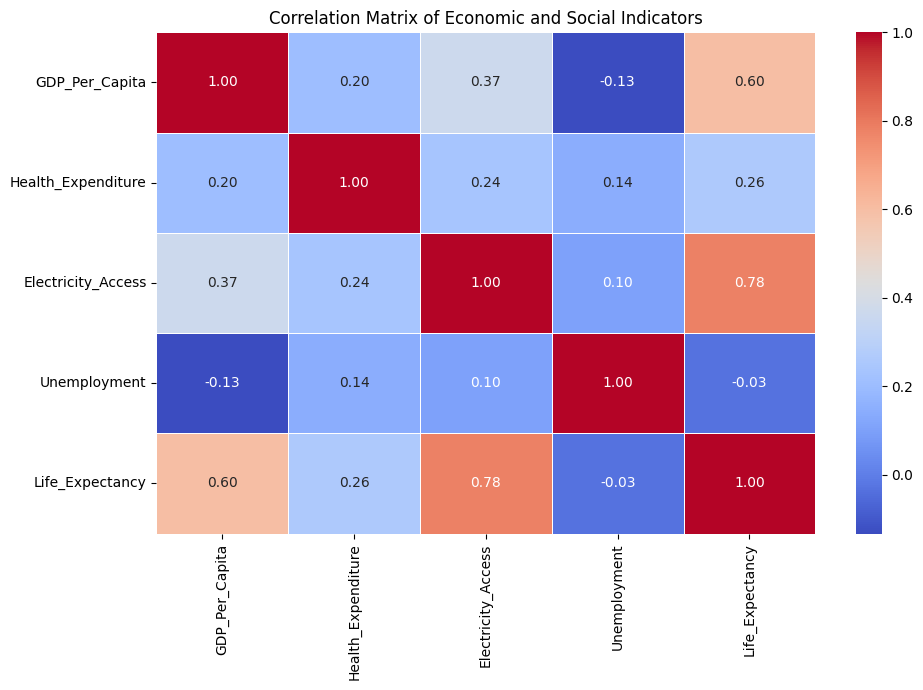

Correlation with Life Expectancy:


Life_Expectancy       1.000000
Electricity_Access    0.781917
GDP_Per_Capita        0.600921
Health_Expenditure    0.259756
Unemployment         -0.034326
Name: Life_Expectancy, dtype: float64

In [5]:
# Calculate correlation matrix
correlation_matrix = df[features].corr()

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Economic and Social Indicators")
plt.tight_layout()
plt.show()

# Correlation with target variable
print("Correlation with Life Expectancy:")

display(
    correlation_matrix["Life_Expectancy"]
    .sort_values(ascending=False)
)

### 2.4 Answers to Business Questions 1–3

**Question 1 — How does GDP per capita relate to life expectancy?**

GDP per capita has a **positive Pearson correlation of 0.601** with life expectancy in the observed country-year data. The correlation heatmap above supports a moderately strong linear relationship. GDP per capita is highly skewed, so the relationship may not be constant at all income levels.

**Question 2 — Does healthcare expenditure relate to life expectancy?**

Healthcare expenditure as a percentage of GDP has a **positive correlation of 0.260**, weaker than the observed association with GDP per capita. This indicator measures the share of national output spent on healthcare, not healthcare spending per person or quality of care.

**Question 3 — How do electricity access and unemployment relate to life expectancy?**

Electricity access has the **strongest positive correlation, 0.782**. Unemployment shows almost no linear association (**-0.034**) in this dataset. The correlation heatmap supports both findings. Neither relationship should be interpreted as causal.


### 2.5 Exploratory Data Analysis Findings

The dataset contains 2,821 observations from 217 countries between 2010 and 2022.

**Data Quality**

- No duplicate records were identified.
- The target variable, Life Expectancy, contains no missing values.
- Unemployment has 13.86% missing values.
- Health Expenditure has 11.88% missing values.
- GDP Per Capita has 2.55% missing values.
- Electricity Access has 0.92% missing values.

**Descriptive Statistics**

- The average life expectancy is approximately 72.10 years.
- Median life expectancy is 73.33 years.
- GDP per capita has a highly uneven distribution, with a mean of $18,444.66 and a median of $6,729.85.
- Electricity access has a median of 99.7%.

**Correlation Analysis**

Electricity Access shows the strongest positive correlation with Life Expectancy (0.782), followed by GDP Per Capita (0.601).

Health Expenditure has a weaker positive correlation (0.260), while Unemployment shows almost no linear correlation (-0.034).

These relationships do not necessarily indicate causation.

**Data Preparation Strategy**

Missing predictor values will be imputed using median values learned exclusively from the training dataset.

A chronological train-test split will be used to evaluate how well the models generalize to later years.

### 2.6 Investigating Potential Outliers

Inspect minimum life expectancy, maximum GDP per capita, and annual changes above 10 years. The 10-year threshold is an exploratory flag, not a rule for automatically removing observations. Keep all records for the main model evaluation.


In [6]:
# Inspect unusually low life expectancy values
print("Lowest life expectancy observations:")

display(
    df.nsmallest(10, "Life_Expectancy")[
        ["Country", "Year", "Life_Expectancy"]
    ]
)

# Inspect unusually high GDP values
print("\nHighest GDP per capita observations:")

display(
    df.nlargest(10, "GDP_Per_Capita")[
        ["Country", "Year", "GDP_Per_Capita"]
    ]
)

Lowest life expectancy observations:


,Country,Year,Life_Expectancy
493,Central African Republic,2022,18.818
490,Central African Republic,2019,31.530
2289,"Somalia, Fed. Rep.",2011,32.453
2321,South Sudan,2017,35.351
2320,South Sudan,2016,36.720
2319,South Sudan,2015,39.757
485,Central African Republic,2014,40.265
492,Central African Republic,2021,40.279
488,Central African Republic,2017,45.231
1092,Haiti,2010,45.577



Highest GDP per capita observations:


,Country,Year,GDP_Per_Capita
1702,Monaco,2022,226052.060665
1701,Monaco,2021,223823.327192
1493,Liechtenstein,2021,201944.830335
1694,Monaco,2014,195693.519541
1699,Monaco,2019,193746.729891
1698,Monaco,2018,188298.389694
1494,Liechtenstein,2022,188055.003235
1693,Monaco,2013,184940.633666
1691,Monaco,2011,179364.009524
1486,Liechtenstein,2014,178735.153021


In [7]:
# Detect unusually large year-to-year changes
df_check = df.sort_values(
    ["Country_Code", "Year"]
).copy()

df_check["Life_Expectancy_Change"] = (
    df_check.groupby("Country_Code")["Life_Expectancy"]
    .diff()
)

unusual_changes = df_check[
    df_check["Life_Expectancy_Change"].abs() > 10
]

print("Observations requiring further investigation:")
display(
    unusual_changes[
        ["Country", "Year", "Life_Expectancy",
         "Life_Expectancy_Change"]
    ].sort_values("Life_Expectancy_Change")
)

print("Total flagged observations:", len(unusual_changes))

Observations requiring further investigation:


,Country,Year,Life_Expectancy,Life_Expectancy_Change
493,Central African Republic,2022,18.818,-21.461
490,Central African Republic,2019,31.530,-20.767
2289,"Somalia, Fed. Rep.",2011,32.453,-16.447
2318,South Sudan,2014,45.625,-12.660
492,Central African Republic,2021,40.279,-10.317
486,Central African Republic,2015,51.934,11.669
1093,Haiti,2011,61.581,16.004
2322,South Sudan,2018,51.905,16.554
2290,"Somalia, Fed. Rep.",2012,49.138,16.685
491,Central African Republic,2020,50.596,19.066


Total flagged observations: 10


## 3. Data Preparation

The prediction target is `Life_Expectancy`. The four predictors are numeric: GDP per capita, health expenditure, electricity access, and unemployment. `Country` and `Country_Code` are identifiers and are deliberately excluded from modeling, so **no categorical encoding is required**. `Year` determines the chronological split and is not included as a predictor.

The dataset has no missing target values. Predictors have missing observations; dropping all incomplete rows would unnecessarily reduce the sample. Each model uses **median imputation fitted on the training portion only** (2010–2019), which handles skewed numeric data and prevents leakage from the testing years (2020–2022).

A 2010–2019 training and 2020–2022 testing split evaluates prediction on later observations of **previously represented countries**, not on completely unseen countries.


In [8]:
# Keep numeric predictors only; Country and Country_Code are identifiers.
# Year is reserved for the chronological train/test split.
feature_columns = [
    "GDP_Per_Capita",
    "Health_Expenditure",
    "Electricity_Access",
    "Unemployment",
]
target_column = "Life_Expectancy"

# Later years are never included when fitting imputers or regressors.
train_df = df.loc[df["Year"] <= 2019].copy()
test_df = df.loc[df["Year"] >= 2020].copy()

x_train = train_df[feature_columns]
y_train = train_df[target_column]
x_test = test_df[feature_columns]
y_test = test_df[target_column]

print("Training observations:", len(x_train))
print("Testing observations:", len(x_test))
print("Features:", feature_columns)


Training observations: 2170
Testing observations: 651
Features: ['GDP_Per_Capita', 'Health_Expenditure', 'Electricity_Access', 'Unemployment']


## 4. Modeling and Evaluation

**Question 4 — Can regression models predict life expectancy using these indicators?**

Compare a mean-only baseline, linear regression, and a random forest. Use **MAE** and **RMSE** (years; lower is better), plus **R²** (larger is better). Accuracy and recall are classification measures and are not appropriate for this continuous regression target.


In [9]:
# Compare a baseline against linear and nonlinear regression models.
models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    ),
}


def build_model_pipeline(estimator):
    """Combine train-only median imputation with a regression estimator."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator),
    ])


def evaluate_regression(pipeline, predictors, actual):
    """Calculate prediction error and goodness of fit on held-out data."""
    predicted = pipeline.predict(predictors)

    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2 Score": r2_score(actual, predicted),
    }


results = []
trained_models = {}

for model_name, estimator in models.items():
    model_pipeline = build_model_pipeline(estimator)
    model_pipeline.fit(x_train, y_train)

    scores = evaluate_regression(model_pipeline, x_test, y_test)
    results.append({"Model": model_name, **scores})
    trained_models[model_name] = model_pipeline

results_df = pd.DataFrame(results)
display(results_df.round(3))


,Model,MAE,RMSE,R2 Score
0,Baseline,6.166,7.706,-0.004
1,Linear Regression,3.321,4.459,0.664
2,Random Forest,2.328,3.463,0.797


### 4.2 Model Performance and Interpretation

Three regression models were evaluated using historical World Bank data.

The training dataset contains 2,170 observations from 2010 to 2019, while the testing dataset contains 651 observations from 2020 to 2022.

### Model Performance

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Baseline | 6.166 | 7.706 | -0.004 |
| Linear Regression | 3.321 | 4.459 | 0.664 |
| Random Forest | 2.328 | 3.463 | 0.797 |

Random Forest achieved the best performance, reducing the Mean Absolute Error by approximately 29.9% compared with Linear Regression.

Its MAE of 2.328 indicates that predictions differ from observed life expectancy by approximately 2.33 years on average.

The R² score of 0.797 indicates that the model explains approximately 79.7% of the variation in life expectancy within the test dataset.

### Limitations

The analysis includes historical observations with unusually large changes in life expectancy, which require additional data quality investigation.

Furthermore, the models were evaluated on later observations from countries already represented in training. Performance when predicting entirely new countries has not been established.

These results demonstrate predictive relationships rather than causal effects.

### 4.3 Answer to Business Question 4

Yes, within the **2020–2022** test period, the random forest produced the strongest performance: **MAE 2.328 years**, **RMSE 3.463 years**, and **R² 0.797**. Linear regression had **MAE 3.321 years**, so random forest's error was roughly **29.9% lower**. The chart and tables below illustrate model accuracy and predictor importance. The model does not establish causal explanations.


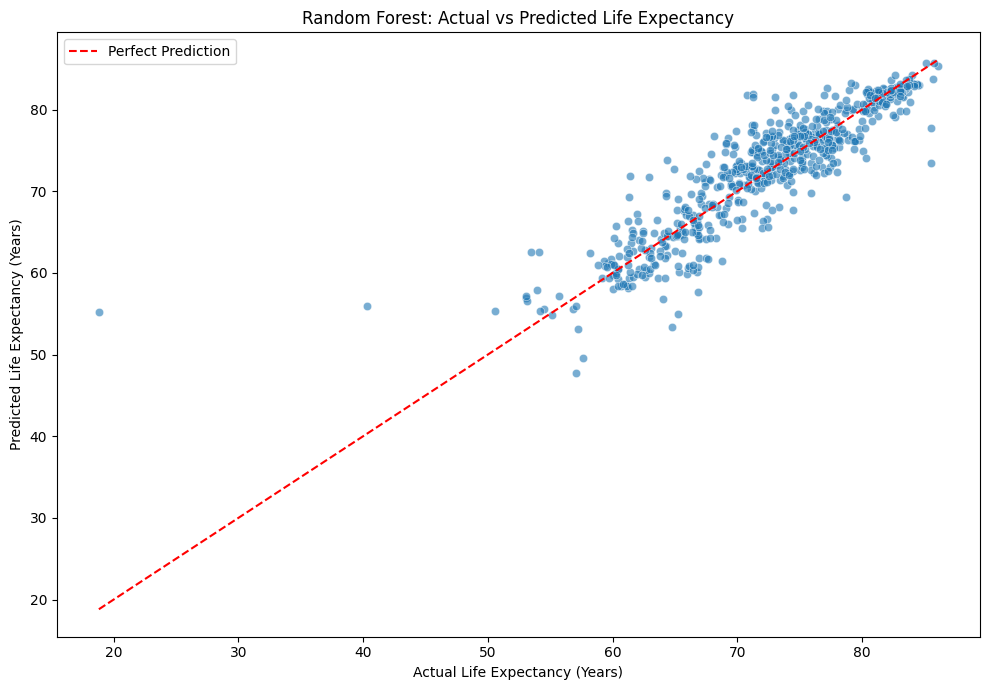

,Country,Year,Life_Expectancy,Predicted,Absolute_Error
493,Central African Republic,2022,18.818000,55.168351,36.350351
492,Central African Republic,2021,40.279000,55.892416,15.613416
1128,"Hong Kong SAR, China",2020,85.496341,73.466991,12.029350
1558,Malawi,2021,64.782000,53.328629,11.453371
180,"Bahamas, The",2021,70.752000,81.763806,11.011806
1012,Greenland,2021,71.261463,81.898333,10.636869
310,Bolivia,2021,61.427000,71.843080,10.416080
1013,Greenland,2022,71.230244,81.495444,10.265200
1557,Malawi,2020,65.216000,55.010538,10.205462
1090,Guyana,2021,64.323000,73.843917,9.520917


In [10]:
# Select the best-performing model
best_model = trained_models["Random Forest"]

# Generate predictions
y_pred = best_model.predict(x_test)

# Actual vs predicted
plt.figure(figsize=(10, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.6
)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(limits, limits, "r--", label="Perfect Prediction")

plt.xlabel("Actual Life Expectancy (Years)")
plt.ylabel("Predicted Life Expectancy (Years)")
plt.title("Random Forest: Actual vs Predicted Life Expectancy")
plt.legend()
plt.tight_layout()
plt.show()

# Identify the largest prediction errors
prediction_results = test_df[
    ["Country", "Year", "Life_Expectancy"]
].copy()

prediction_results["Predicted"] = y_pred
prediction_results["Absolute_Error"] = abs(
    prediction_results["Life_Expectancy"] -
    prediction_results["Predicted"]
)

display(
    prediction_results.nlargest(10, "Absolute_Error")
)

,Feature,Importance
2,Electricity_Access,0.694545
0,GDP_Per_Capita,0.185705
1,Health_Expenditure,0.060024
3,Unemployment,0.059726


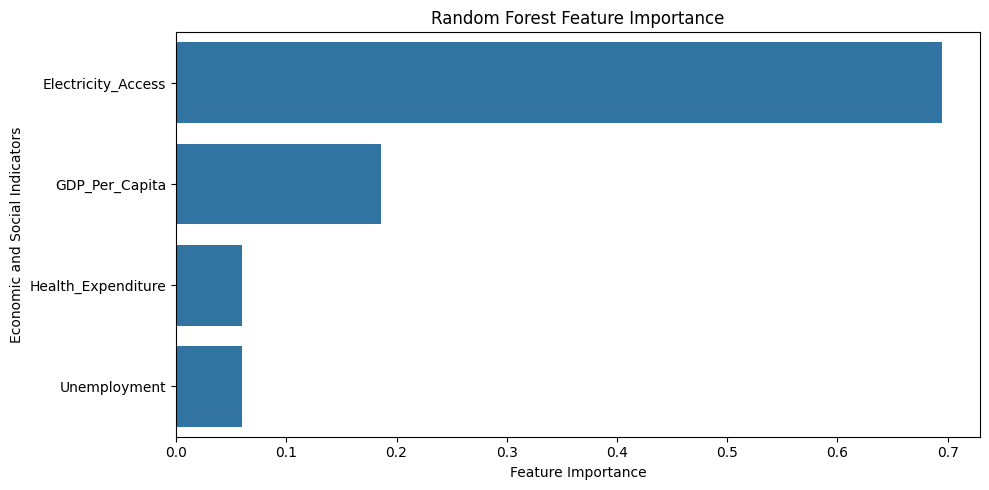

In [11]:
# Extract feature importance from Random Forest
rf_model = best_model.named_steps["model"]

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Economic and Social Indicators")

plt.tight_layout()
plt.show()

### 4.4 Interpreting Model Features

Random forest's fitted feature importance ranks electricity access highest (**0.6945**), followed by GDP per capita (**0.1857**). These values reflect how the estimator used features, **not** the fraction of life expectancy caused by each variable. Correlated predictors can share or distort these importance measures.


## 5. Applying the Model to a New Scenario

Consider a hypothetical country with GDP per capita **$15,000**, healthcare spending **7% of GDP**, electricity access **100%**, and unemployment **6%**. The model estimates **76.77 years** of life expectancy. The result illustrates model behavior rather than a guaranteed outcome for a real country.


In [12]:
# Hypothetical country scenario
new_country = pd.DataFrame([{
    "GDP_Per_Capita": 15000,
    "Health_Expenditure": 7.0,
    "Electricity_Access": 100.0,
    "Unemployment": 6.0
}])

# Generate life expectancy prediction
predicted_life_expectancy = best_model.predict(
    new_country
)[0]

print("Hypothetical Country Indicators:")
display(new_country)

print(
    f"Predicted Life Expectancy: "
    f"{predicted_life_expectancy:.2f} years"
)

Hypothetical Country Indicators:


,GDP_Per_Capita,Health_Expenditure,Electricity_Access,Unemployment
0,15000,7.0,100.0,6.0


Predicted Life Expectancy: 76.77 years


## 6. Model Evaluation: Sensitivity and Limitations

For an **exploratory sensitivity check**, compare test scores for all 651 observations with scores on 648 observations after excluding three records flagged for a year-over-year change greater than 10 years. The original full-test scores remain primary: filtering based on observed outcomes is **not** an unbiased measure of deployment accuracy.


In [13]:
# Sensitivity analysis: evaluate performance without
# flagged year-over-year changes in the test set.

flagged_indices = df_check.loc[
    df_check["Life_Expectancy_Change"].abs() > 10
].index

regular_mask = ~x_test.index.isin(flagged_indices)

y_pred_series = pd.Series(
    best_model.predict(x_test),
    index=x_test.index
)

print("Original test MAE:",
      round(mean_absolute_error(y_test, y_pred_series), 3))

print("Unflagged test MAE:",
      round(mean_absolute_error(
          y_test.loc[regular_mask],
          y_pred_series.loc[regular_mask]
      ), 3))

print("Unflagged test R²:",
      round(r2_score(
          y_test.loc[regular_mask],
          y_pred_series.loc[regular_mask]
      ), 3))

print("Flagged test observations:",
      (~regular_mask).sum())

Original test MAE: 2.328
Unflagged test MAE: 2.252
Unflagged test R²: 0.818
Flagged test observations: 3


## 7. Conclusions and Communication

The four business questions have been answered with descriptive correlations, distribution and correlation plots, model comparison scores, and an illustrative prediction. Electricity access and GDP per capita were the strongest correlates, and random forest outperformed the baseline and linear regression on later-year observations. These associations are not causal.

**Limitations:** the analysis uses repeated countries across years, possible inconsistent source estimates and outliers, a small predictor set, and a testing window affected by events in 2020–2022. The public-facing summary is available in [blog_post.md](blog_post.md).

**CRISP-DM steps:** (1) business understanding; (2) data understanding, gathering and assessment; (3) data preparation; (4) modeling; (5) evaluation; (6) communication and illustrative application.
